11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training images: (60000, 784)
Testing images: (10000, 784)


Model: "Autoencoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_image (InputLayer)        │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ latent_representation (Dense)   │ (None, 32)             │         4,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │         4,224 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 784)            │       101,136 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 209,968 (820.19 KB)

 Trainable params: 209,968 (820.19 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/5
235/235 ━━━━━━━━━━━━━━━━━━━━ 5s 14ms/step - loss: 0.0571 - val_loss: 0.0309
Epoch 2/5
235/235 ━━━━━━━━━━━━━━━━━━━━ 5s 14ms/step - loss: 0.0251 - val_loss: 0.0208
Epoch 3/5
235/235 ━━━━━━━━━━━━━━━━━━━━ 5s 19ms/step - loss: 0.0189 - val_loss: 0.0167
Epoch 4/5
235/235 ━━━━━━━━━━━━━━━━━━━━ 3s 13ms/step - loss: 0.0161 - val_loss: 0.0147
Epoch 5/5
235/235 ━━━━━━━━━━━━━━━━━━━━ 4s 18ms/step - loss: 0.0144 - val_loss: 0.0134


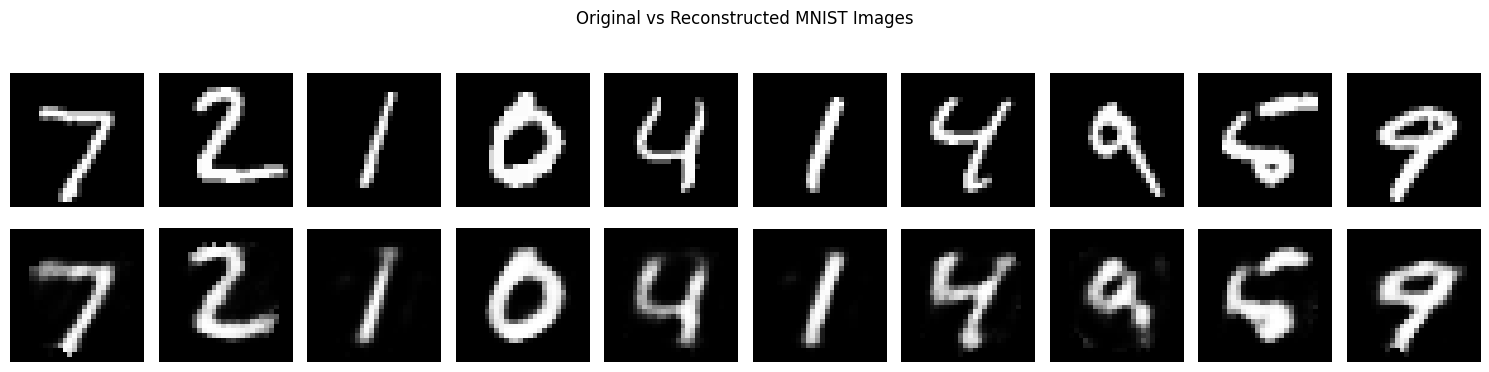

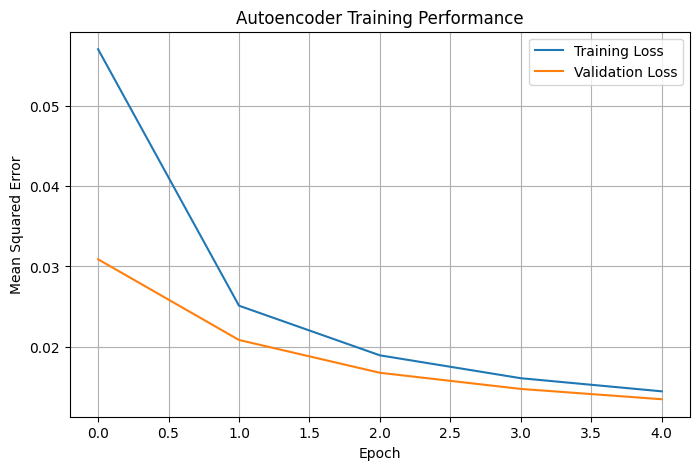

Test Reconstruction MSE: 0.013447
Model saved as mnist_autoencoder.keras


In [1]:

# PROJECT 2: IMAGE RECONSTRUCTION USING AUTOENCODER
# Dataset: MNIST | Framework: TensorFlow / Keras

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, Model

# 1. Load the MNIST dataset
(x_train, _), (x_test, _) = tf.keras.datasets.mnist.load_data()

# 2. Normalize pixel values and flatten images
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

x_train = x_train.reshape(-1, 784)
x_test = x_test.reshape(-1, 784)

print("Training images:", x_train.shape)
print("Testing images:", x_test.shape)

# 3. Build the encoder
input_img = layers.Input(shape=(784,), name="input_image")
encoded = layers.Dense(128, activation="relu")(input_img)
latent = layers.Dense(32, activation="relu",
                      name="latent_representation")(encoded)

# 4. Build the decoder
decoded = layers.Dense(128, activation="relu")(latent)
output_img = layers.Dense(784, activation="sigmoid")(decoded)

# 5. Create and compile the autoencoder
autoencoder = Model(input_img, output_img, name="Autoencoder")
autoencoder.compile(optimizer="adam", loss="mse")

autoencoder.summary()

# 6. Train the model
history = autoencoder.fit(
    x_train, x_train,
    epochs=5,
    batch_size=256,
    shuffle=True,
    validation_data=(x_test, x_test),
    verbose=1
)

# 7. Reconstruct test images
reconstructed = autoencoder.predict(x_test[:10], verbose=0)

# 8. Display original and reconstructed images
plt.figure(figsize=(15, 4))

for i in range(10):
    # Original image
    plt.subplot(2, 10, i + 1)
    plt.imshow(x_test[i].reshape(28, 28), cmap="gray")
    plt.axis("off")
    if i == 0:
        plt.ylabel("Original", fontsize=10)

    # Reconstructed image
    plt.subplot(2, 10, i + 11)
    plt.imshow(reconstructed[i].reshape(28, 28), cmap="gray")
    plt.axis("off")
    if i == 0:
        plt.ylabel("Reconstructed", fontsize=10)

plt.suptitle("Original vs Reconstructed MNIST Images")
plt.tight_layout()
plt.show()

# 9. Plot training and validation loss
plt.figure(figsize=(8, 5))
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error")
plt.title("Autoencoder Training Performance")
plt.legend()
plt.grid(True)
plt.show()

# 10. Evaluate reconstruction quality
predictions = autoencoder.predict(x_test, verbose=0)
mse = np.mean((x_test - predictions) ** 2)

print(f"Test Reconstruction MSE: {mse:.6f}")

# 11. Save the trained model
autoencoder.save("mnist_autoencoder.keras")
print("Model saved as mnist_autoencoder.keras")
